# Task 1 – Titanic Passenger Survival Prediction System
**🔗 Live Deployment Link:**

**Student Name:** Asna Aqeel

**Reg. No:** SP24-BSE-016



## The ML cycle 
| Phase | What we do |
|---|---|
| 1. Data | Collection, understanding, preprocessing, label encoding |
| 2. Training | Train several classifiers on the training split |
| 3. Testing | Evaluate on unseen test split, pick best model |
| 4. Deployment | Save the model (`.pkl`) and serve it on the cloud |

## Phase 1 – Data
### Step 1: Import libraries

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
sns.set_style("whitegrid")

### Step 2: Data collection (load the dataset)
 `titanic.csv` 

In [ ]:
df = pd.read_csv("titanic.csv")

df = df.rename(columns={"survived":"Survived","pclass":"Pclass","sex":"Sex","age":"Age",
                        "sibsp":"SibSp","parch":"Parch","fare":"Fare","embarked":"Embarked"})
df = df[["Survived","Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]]
print("Shape:", df.shape)
df.head()

Shape: (891, 8)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### Step 3: Data understanding

In [3]:
df.info()
print()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 60.9 KB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
Embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nClass balance (Survived):")
print(df["Survived"].value_counts())

Missing values per column:
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

Class balance (Survived):
Survived
0    549
1    342
Name: count, dtype: int64


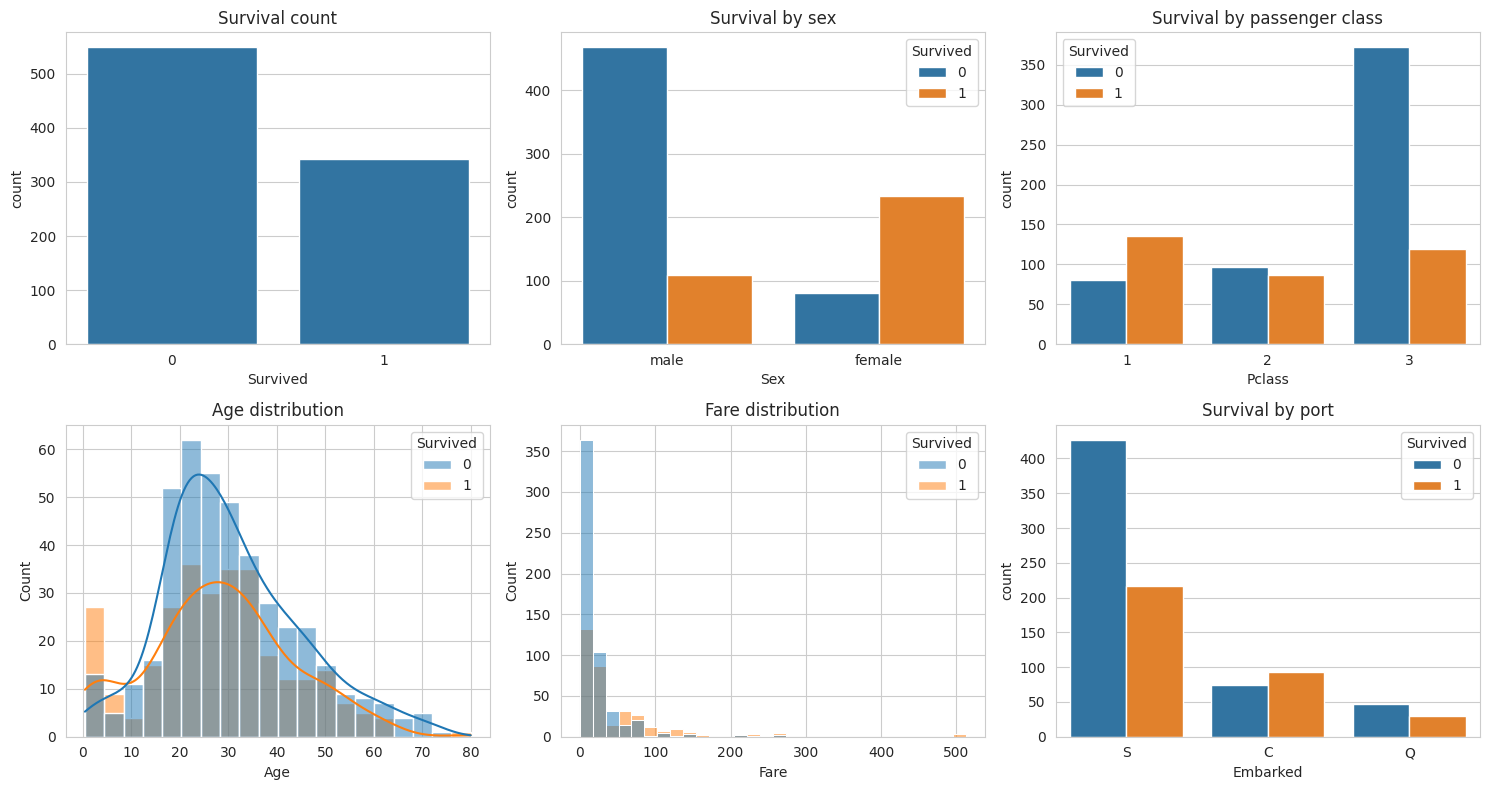

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(x="Survived", data=df, ax=ax[0,0]);                ax[0,0].set_title("Survival count")
sns.countplot(x="Sex", hue="Survived", data=df, ax=ax[0,1]);     ax[0,1].set_title("Survival by sex")
sns.countplot(x="Pclass", hue="Survived", data=df, ax=ax[0,2]);  ax[0,2].set_title("Survival by passenger class")
sns.histplot(data=df, x="Age", hue="Survived", kde=True, ax=ax[1,0]); ax[1,0].set_title("Age distribution")
sns.histplot(data=df, x="Fare", hue="Survived", bins=30, ax=ax[1,1]); ax[1,1].set_title("Fare distribution")
sns.countplot(x="Embarked", hue="Survived", data=df, ax=ax[1,2]);     ax[1,2].set_title("Survival by port")
plt.tight_layout(); plt.show()

**Observations:** women and first-class passengers survived at a much higher rate; most passengers did not survive (imbalanced towards 0). `Age` has many missing values and `Embarked` a couple.

### Step 4: Data preprocessing
* `Age` (numeric, missing) → fill with the **median**
* `Embarked` (categorical, 2 missing) → fill with the **mode**
* remove duplicate rows if any

In [5]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print("Duplicates removed:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Missing values left:", df.isnull().sum().sum())
print("Final shape:", df.shape)

Duplicates removed: 116
Missing values left: 0
Final shape: (775, 8)


### Step 5: Label encoding
Machine-learning models need numbers. `Sex` and `Embarked` are text, so we convert them with `LabelEncoder`. The fitted encoders are **saved** so the deployed app can encode user input in exactly the same way.

In [6]:
encoders = {}
for col in ["Sex", "Embarked"]:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le
    print(col, "->", dict(zip(le.classes_, le.transform(le.classes_))))
df.head()

Sex -> {'female': np.int64(0), 'male': np.int64(1)}
Embarked -> {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


### Step 6: Feature / label split and train–test split

In [7]:
FEATURES = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]
X = df[FEATURES]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (620, 7)  Test: (155, 7)


## Phase 2 – Training
We train four different classifiers and compare them with 5-fold cross-validation on the training data.

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
}
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean()
    m.fit(X_train, y_train)
    print(f"{name:20s} CV accuracy = {cv:.3f}")

Logistic Regression  CV accuracy = 0.761
Decision Tree        CV accuracy = 0.787
KNN                  CV accuracy = 0.665
Random Forest        CV accuracy = 0.797


## Phase 3 – Testing / Evaluation
All models are evaluated on the **unseen** 20 % test set.

In [9]:
rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append([name, accuracy_score(y_test,p), precision_score(y_test,p),
                 recall_score(y_test,p), f1_score(y_test,p)])
results = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1"]).set_index("Model").round(3)
results.sort_values("Accuracy", ascending=False)

,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.813,0.843,0.672,0.748
Decision Tree,0.806,0.783,0.734,0.758
Logistic Regression,0.768,0.719,0.719,0.719
KNN,0.716,0.647,0.688,0.667


Best model: Random Forest
              precision    recall  f1-score   support

Not survived       0.80      0.91      0.85        91
    Survived       0.84      0.67      0.75        64

    accuracy                           0.81       155
   macro avg       0.82      0.79      0.80       155
weighted avg       0.82      0.81      0.81       155



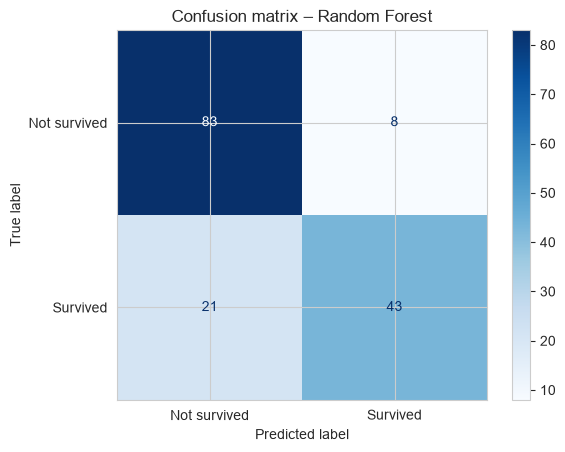

In [14]:
best_name = results["Accuracy"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)
pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["Not survived","Survived"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Not survived","Survived"]).plot(cmap="Blues")
plt.title(f"Confusion matrix – {best_name}"); plt.show()

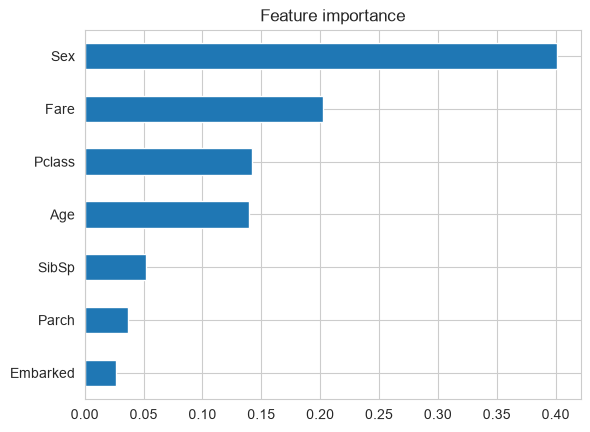

In [15]:
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind="barh", title="Feature importance"); plt.show()

## Phase 4 – Deployment
### Step 1: Save the trained model


In [19]:
artifact = {"model": best_model, "encoders": encoders, "features": FEATURES, "model_name": best_name}
joblib.dump(artifact, "titanic_model.pkl")
print("Saved titanic_model.pkl")

Saved titanic_model.pkl


### Step 2: Test loading the model and predicting for a new passenger

In [17]:
art = joblib.load("titanic_model.pkl")
new = pd.DataFrame([{
    "Pclass": 1, "Sex": art["encoders"]["Sex"].transform(["female"])[0], "Age": 29,
    "SibSp": 0, "Parch": 0, "Fare": 80.0,
    "Embarked": art["encoders"]["Embarked"].transform(["S"])[0]}])[art["features"]]
prob = art["model"].predict_proba(new)[0,1]
print("Prediction:", "SURVIVED" if prob >= 0.5 else "DID NOT SURVIVE", f"(probability {prob:.2f})")

Prediction: SURVIVED (probability 0.96)


### Step 3: Deploy to the cloud (PythonAnywhere)
 `flask_app.py`, `titanic_model.pkl`, `requirements.txt`.



In [12]:
import sklearn; print('scikit-learn version used for training:', sklearn.__version__)

scikit-learn version used for training: 1.9.1


## Conclusion
We built a complete ML system: data collection → understanding → preprocessing → label encoding → training → testing → deployment. The best model reaches roughly 80 % test accuracy; sex, passenger class and fare/age are the strongest predictors, matching the historical record ("women and children first").